In [1]:
import sys
from pathlib import Path
import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

# Agregamos la raíz del proyecto al path para importar nuestros módulos de src/
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import CreditRiskPreprocessor
from src.metrics import (
    calcular_ks,
    evaluar_modelo_crediticio,
    optimizar_umbral_financiero,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 1. Lectura de datos desde nuestra base analítica DuckDB
DB_PATH = PROJECT_ROOT / "data" / "processed" / "credit_risk.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)
df = con.execute("SELECT * FROM solicitudes_credito").df()
con.close()

# 2. Separación de predictores (X) y variable objetivo (y)
TARGET = "SeriousDlqin2yrs"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# 3. División Train / Test estratificada (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Train shape: {X_train.shape} | Tasa default Train: {y_train.mean()*100:.2f}%")
print(f"Test shape:  {X_test.shape} | Tasa default Test:  {y_test.mean()*100:.2f}%")

Train shape: (120000, 11) | Tasa default Train: 6.68%
Test shape:  (30000, 11) | Tasa default Test:  6.68%


In [2]:
# Inspeccionamos qué variables entrega nuestro transformador (solo ajustado en Train)
prep_check = CreditRiskPreprocessor()
X_train_transformed = prep_check.fit_transform(X_train)

print(f"Total de variables tras Feature Engineering: {X_train_transformed.shape[1]}")
display(X_train_transformed.head())

Total de variables tras Feature Engineering: 19


,age,NumberOfTime30-59DaysPastDueNotWorse,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,flag_ingreso_no_declarado,flag_dependientes_nulos,flag_codigo_especial_atraso,RevolvingUtilization_clean,flag_sobreutilizacion_100,DebtRatio_clean,gasto_mensual_estimado,ingreso_per_capita,total_atrasos_historicos,indice_severidad_atrasos,ratio_lineas_inmobiliarias
57836,62.0,0.0,5390.0,5.0,0.0,1.0,0.0,2.0,1,0,0,0.114987,0,3.000979,16175.276923,1796.666667,0.0,0.0,0.166667
132895,73.0,0.0,3800.0,6.0,0.0,1.0,0.0,0.0,0,0,0,0.008705,0,0.498553,1894.501446,3800.000000,0.0,0.0,0.142857
27981,32.0,0.0,3716.0,8.0,0.0,0.0,0.0,2.0,0,0,0,0.214501,0,0.211999,787.788002,1238.666667,0.0,0.0,0.000000
37852,60.0,0.0,5390.0,5.0,0.0,0.0,0.0,0.0,1,0,0,1.000000,0,3.000979,16175.276923,5390.000000,0.0,0.0,0.000000
103813,60.0,0.0,3000.0,10.0,0.0,1.0,0.0,0.0,0,0,0,0.230493,0,1.017328,3051.982671,3000.000000,0.0,0.0,0.090909


In [3]:
# Calculamos el ratio de desbalance exclusivamente sobre Train
ratio_desbalance = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Ratio negativos/positivos en Train: {ratio_desbalance:.2f}")

# Definimos los pipelines candidatos
modelos = {
    "Regresión Logística (Baseline)": Pipeline([
        ("prep", CreditRiskPreprocessor()),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("prep", CreditRiskPreprocessor()),
        ("clf", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_leaf=20,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42,
        )),
    ]),
    "LightGBM": Pipeline([
        ("prep", CreditRiskPreprocessor()),
        ("clf", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            subsample_for_bin=50000,
            colsample_bytree=0.8,
            subsample=0.8,
            random_state=42,
            verbose=-1,
        )),
    ]),
    "XGBoost": Pipeline([
        ("prep", CreditRiskPreprocessor()),
        ("clf", XGBClassifier(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=5,
            colsample_bytree=0.8,
            subsample=0.8,
            eval_metric="logloss",
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_cv = []
probabilidades_oof = {}  # Out-Of-Fold predictions en Train

for nombre, pipeline in modelos.items():
    print(f"Evaluando {nombre} en 5-Fold CV...")
    # Obtenemos probabilidades fuera de pliegue (sin data leakage)
    y_prob_oof = cross_val_predict(
        pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    probabilidades_oof[nombre] = y_prob_oof

    metricas = evaluar_modelo_crediticio(
        y_train, y_prob_oof, umbral=0.50, nombre_modelo=nombre
    )
    resultados_cv.append(metricas)

df_resultados_cv = pd.DataFrame(resultados_cv).sort_values(by="ROC_AUC", ascending=False)
display(df_resultados_cv)

Ratio negativos/positivos en Train: 13.96
Evaluando Regresión Logística (Baseline) en 5-Fold CV...
Evaluando Random Forest en 5-Fold CV...
Evaluando LightGBM en 5-Fold CV...
Evaluando XGBoost en 5-Fold CV...


,Modelo,Umbral,ROC_AUC,PR_AUC,KS_Stat,Recall_Default,Precision_Default,F2_Score
3,XGBoost,0.5,0.8654,0.4027,0.5766,0.1863,0.5938,0.2159
2,LightGBM,0.5,0.8647,0.4003,0.5769,0.1844,0.5964,0.2140
1,Random Forest,0.5,0.8634,0.3971,0.5727,0.7298,0.2421,0.5202
0,Regresión Logística (Baseline),0.5,0.8555,0.3791,0.5516,0.7356,0.2201,0.5009


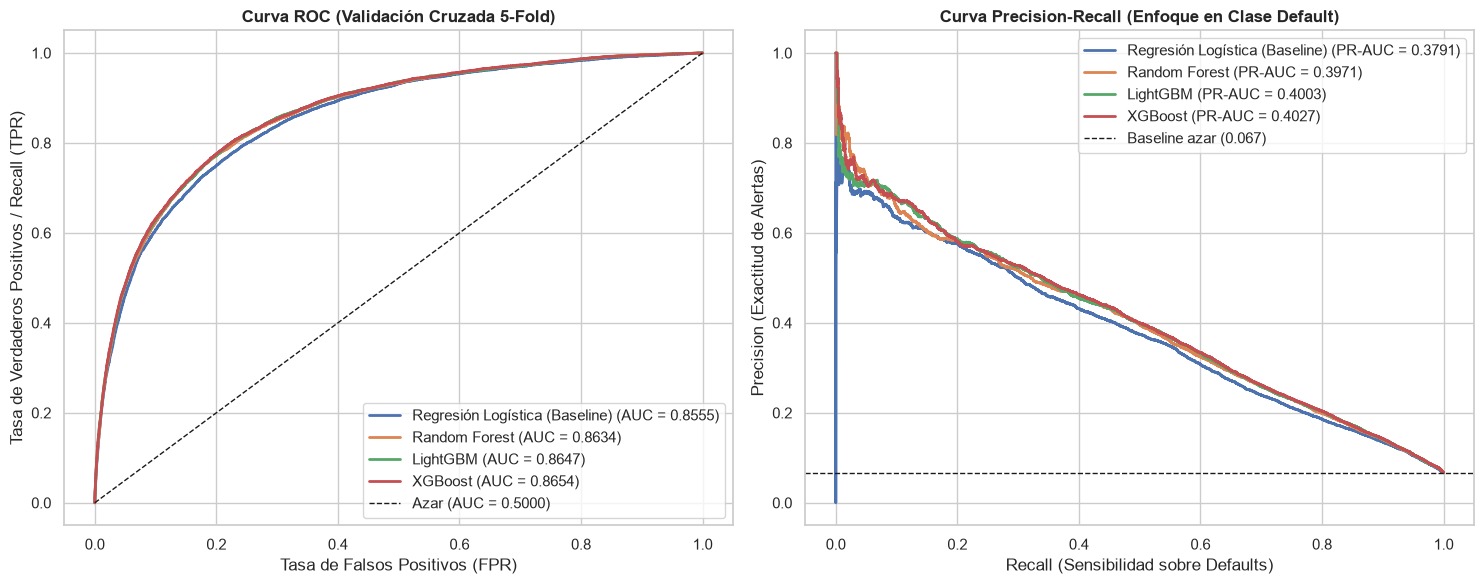

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for nombre, y_prob in probabilidades_oof.items():
    # Curva ROC
    fpr, tpr, _ = roc_curve(y_train, y_prob)
    auc_score = df_resultados_cv.loc[df_resultados_cv["Modelo"] == nombre, "ROC_AUC"].values[0]
    axes[0].plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc_score:.4f})")

    # Curva Precision-Recall
    precision, recall, _ = precision_recall_curve(y_train, y_prob)
    pr_score = df_resultados_cv.loc[df_resultados_cv["Modelo"] == nombre, "PR_AUC"].values[0]
    axes[1].plot(recall, precision, lw=2, label=f"{nombre} (PR-AUC = {pr_score:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5000)")
axes[0].set_title("Curva ROC (Validación Cruzada 5-Fold)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos / Recall (TPR)")
axes[0].legend(loc="lower right")

tasa_base = y_train.mean()
axes[1].axhline(tasa_base, color="k", linestyle="--", lw=1, label=f"Baseline azar ({tasa_base:.3f})")
axes[1].set_title("Curva Precision-Recall (Enfoque en Clase Default)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall (Sensibilidad sobre Defaults)")
axes[1].set_ylabel("Precision (Exactitud de Alertas)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [5]:
# Seleccionamos automáticamente el mejor modelo según ROC-AUC en validación cruzada
nombre_ganador = df_resultados_cv.iloc[0]["Modelo"]
pipeline_ganador = modelos[nombre_ganador]
print(f"Modelo seleccionado: {nombre_ganador}")

# 1. Entrenamos sobre todo el conjunto Train (120.000 registros)
pipeline_ganador.fit(X_train, y_train)

# 2. Predecimos probabilidades sobre el conjunto de Test intacto (30.000 registros)
y_prob_test = pipeline_ganador.predict_proba(X_test)[:, 1]

# 3. Optimizamos el umbral de corte financiero usando las probabilidades Out-Of-Fold de Train
# (Importante: el umbral óptimo también se aprende en Train para no sobreajustar a Test)
umbral_optimo, df_sim_train = optimizar_umbral_financiero(
    y_train,
    probabilidades_oof[nombre_ganador],
    ganancia_buen_pagador=1000.0,
    perdida_default=5000.0,
)
print(f"Umbral óptimo aprendido en Train (máximo beneficio neto): {umbral_optimo:.3f}")

# 4. Evaluamos en Test comparando el umbral estándar (0.50) vs el umbral financiero óptimo
res_test_default = evaluar_modelo_crediticio(
    y_test, y_prob_test, umbral=0.50, nombre_modelo=f"{nombre_ganador} (Umbral 0.50)"
)
res_test_optimo = evaluar_modelo_crediticio(
    y_test, y_prob_test, umbral=umbral_optimo, nombre_modelo=f"{nombre_ganador} (Umbral Óptimo {umbral_optimo})"
)
display(pd.DataFrame([res_test_default, res_test_optimo]))

# 5. Guardamos el pipeline completo y la metadata de umbral en models/
MODEL_PATH = PROJECT_ROOT / "models" / "modelo_crediticio.joblib"
artefacto_produccion = {
    "pipeline": pipeline_ganador,
    "nombre_modelo": nombre_ganador,
    "umbral_optimo": umbral_optimo,
    "metricas_test": res_test_optimo,
    "columnas_entrada": X_train.columns.tolist(),
}
joblib.dump(artefacto_produccion, MODEL_PATH)
print(f"\nArtefacto de producción guardado exitosamente en: {MODEL_PATH}")

Modelo seleccionado: XGBoost
Umbral óptimo aprendido en Train (máximo beneficio neto): 0.170


,Modelo,Umbral,ROC_AUC,PR_AUC,KS_Stat,Recall_Default,Precision_Default,F2_Score
0,XGBoost (Umbral 0.50),0.50,0.8697,0.4084,0.5844,0.1950,0.6006,0.2255
1,XGBoost (Umbral Óptimo 0.17),0.17,0.8697,0.4084,0.5844,0.5636,0.3686,0.5097



Artefacto de producción guardado exitosamente en: C:\Users\Usuario\OneDrive\Desktop\Maxi\FACULTAD\PROYECTOS Maxi\Proyecto Scoring-Riesgo-Crediticio-ML\models\modelo_crediticio.joblib
